# 商品关联与交叉销售分析

同一订单里商品如何组合：多件订单占比与品类共现组合。

多件商品订单占比 3.3% | 单件订单占比 96.7%


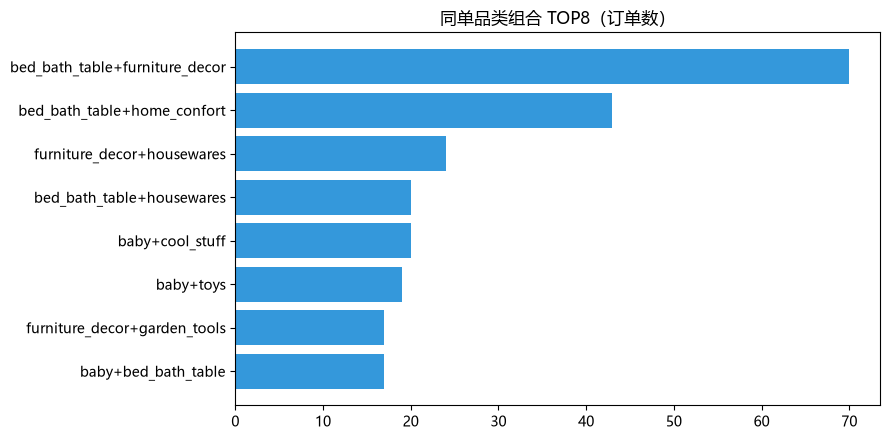

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from itertools import combinations
from collections import Counter

items = pd.read_csv('data/order_items_clean.csv')
products = pd.read_csv('data/products_clean.csv')
it = items.merge(products[['product_id', 'product_category_name_english']], on='product_id')

cnt = it.groupby('order_id')['product_id'].nunique()
print('多件商品订单占比 %.1f%% | 单件订单占比 %.1f%%' % ((cnt > 1).mean() * 100, (cnt == 1).mean() * 100))

multi = it[it['order_id'].isin(cnt[cnt > 1].index)]
pairs = Counter()
for _, grp in multi.groupby('order_id'):
    cats = sorted(set(grp['product_category_name_english'].dropna()))
    pairs.update(combinations(cats, 2))
top = pd.Series(dict(pairs)).sort_values(ascending=False).head(8)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(['+'.join(p) for p in top.index[::-1]], top.values[::-1], color='#3498db')
ax.set_title('同单品类组合 TOP8（订单数）')
plt.tight_layout(); plt.show()


## 结论

- **交叉销售几乎空白**：仅 3.3% 的订单包含多件商品，96.7% 为单件——购物篮深度极低，这是平台最大的增量空间之一。
- **强关联集中在"家居场景"**：床品餐桌+家具装饰（70 单）、床品餐桌+家用舒适（43 单）、家具装饰+厨房用品（24 单）——家居类商品天然互补。
- **建议**：①家居类订单包裹内/详情页推荐互补品；②设置"凑单免运费"门槛（同时也能缓解单件订单运费敏感问题）；③关联度高的品类做联合促销。

## 业务解读

- 96.7% 订单为单件——购物篮深度极低。对比成熟电商（多件率 20–40%），这是 Olist 最大的 GMV 杠杆：**不需要新客户，老订单加一件商品即提升客单价**。
- 多件率低的可能原因：①无「常一起购买」推荐位；②单件免运费心理（加一件触发运费重算）；③平台起家于长尾单品撮合，尚未做场景化运营。
- 强关联集中在「家居场景」（床品+家具装饰、床品+厨房用品），符合「房间级购物」直觉——家居品类适合做场景化套装（如「卧室焕新套装」）。
- 与品类分析联动：床品餐桌既是销量第一又是关联枢纽品类，是交叉销售试验的首选流量入口。

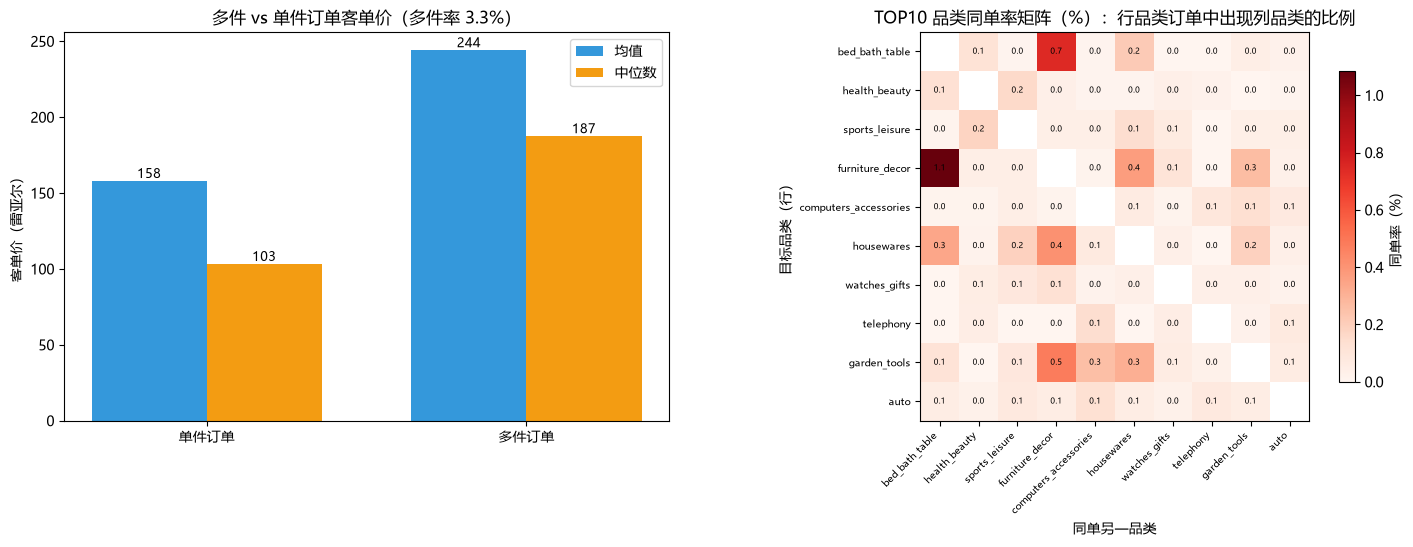

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# ① 多件 vs 单件订单客单价对比（均值 + 中位数）
pays = pd.read_csv('data/order_payments_clean.csv').groupby('order_id')['payment_value'].sum()
basket = pd.DataFrame({'cnt': cnt, 'pay': pays.reindex(cnt.index)})
grp = basket.groupby(basket['cnt'] > 1)['pay'].agg(['mean', 'median'])
xs = np.arange(2)
axes[0].bar(xs - .18, grp['mean'].values, .36, label='均值', color='#3498db')
axes[0].bar(xs + .18, grp['median'].values, .36, label='中位数', color='#f39c12')
axes[0].set_xticks(xs, ['单件订单', '多件订单'])
axes[0].set_ylabel('客单价（雷亚尔）')
axes[0].set_title(f'多件 vs 单件订单客单价（多件率 {(cnt > 1).mean():.1%}）')
for i, (mv, dv) in enumerate(zip(grp['mean'], grp['median'])):
    axes[0].text(i - .18, mv, f'{mv:.0f}', ha='center', va='bottom', fontsize=9)
    axes[0].text(i + .18, dv, f'{dv:.0f}', ha='center', va='bottom', fontsize=9)
axes[0].legend()

# ② 件数 TOP10 品类共现热力图：同单率 = 两品类同单订单数 / 行品类订单数
cat_top = it['product_category_name_english'].value_counts().head(10)
cats = list(cat_top.index)
n_ord = it.groupby('product_category_name_english')['order_id'].nunique()
mat = pd.DataFrame(np.nan, index=cats, columns=cats)
for a in cats:
    for b in cats:
        if a == b:
            continue
        mat.loc[a, b] = pairs.get(tuple(sorted((a, b))), 0) / n_ord[a] * 100
im = axes[1].imshow(np.ma.masked_invalid(mat.values), cmap='Reds')
axes[1].set_xticks(range(10), cats, rotation=45, ha='right', fontsize=7)
axes[1].set_yticks(range(10), cats, fontsize=7)
axes[1].set_xlabel('同单另一品类'); axes[1].set_ylabel('目标品类（行）')
axes[1].set_title('TOP10 品类同单率矩阵（%）：行品类订单中出现列品类的比例')
for i in range(10):
    for j in range(10):
        if i != j and not np.isnan(mat.values[i, j]):
            axes[1].text(j, i, f'{mat.values[i, j]:.1f}', ha='center',
                         va='center', fontsize=6)
plt.colorbar(im, ax=axes[1], shrink=.8, label='同单率（%）')

plt.tight_layout()
plt.show()